In [1]:
import os
import json
import random
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

import cv2
from skimage import measure, morphology
from skimage.measure import regionprops

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

import kagglehub
ROOT = Path(kagglehub.competition_download("filament-segmentation-2026"))
print("Dataset root:", ROOT)


Dataset root: /kaggle/input/competitions/filament-segmentation-2026


In [2]:
# Adjust these two lines only if the folder names differ slightly
TRAIN_DIR = next(ROOT.rglob("train_images"))
TEST_DIR  = next(ROOT.rglob("test_images"))

IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

train_paths = sorted(p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
test_paths  = sorted(p for p in TEST_DIR.iterdir()  if p.suffix.lower() in IMG_EXTS)

json_files = sorted(ROOT.rglob("*.json"))

print(f"Train images: {len(train_paths)}")   # expect 707
print(f"Test images:  {len(test_paths)}")    # expect 180
print("JSON files:")
for j in json_files:
    print("  ", j.relative_to(ROOT))

# Naming pattern check
print("\nFirst 5 train names:", [p.name for p in train_paths[:5]])
print("First 5 test names: ", [p.name for p in test_paths[:5]])

def load_image(path):
    img = np.array(Image.open(path))
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img.astype(np.float32)

def norm01(img, lo_p=1, hi_p=99):
    lo, hi = np.percentile(img, [lo_p, hi_p])
    if hi <= lo:
        return np.zeros_like(img)
    return np.clip((img - lo) / (hi - lo), 0, 1)


Train images: 707
Test images:  180
JSON files:
   MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json

First 5 train names: ['20110109104734Ch.jpeg', '20110114105034Ch.jpeg', '20110119082634Lh.jpeg', '20110123174914Mh.jpeg', '20110128174814Mh.jpeg']
First 5 test names:  ['20110120105534Ch.jpeg', '20110130110334Ch.jpeg', '20110214175414Mh.jpeg', '20110329082654Uh.jpeg', '20110408083214Th.jpeg']


In [3]:
ANN_PATH = json_files[0]   # change index if there are several
with open(ANN_PATH) as f:
    ann_raw = json.load(f)

print("Top-level type:", type(ann_raw).__name__)
if isinstance(ann_raw, dict):
    for k, v in ann_raw.items():
        desc = f"list[{len(v)}]" if isinstance(v, list) else type(v).__name__
        print(f"  {k}: {desc}")

# Peek at actual content — THIS tells us polygon vs RLE vs mask
print(json.dumps(ann_raw, indent=2)[:2500])

# ---- COCO-style parser (images + annotations keys) ----
# If the peek above shows a different schema, we adapt this cell only.

IS_COCO = isinstance(ann_raw, dict) and "images" in ann_raw and "annotations" in ann_raw
print("COCO-style:", IS_COCO)

if IS_COCO:
    images_info = {im["id"]: im for im in ann_raw["images"]}
    anns_by_image = defaultdict(list)
    for a in ann_raw["annotations"]:
        anns_by_image[a["image_id"]].append(a)

    # What does one annotation look like?
    sample_ann = ann_raw["annotations"][0]
    print("Annotation keys:", list(sample_ann.keys()))
    seg = sample_ann.get("segmentation")
    if isinstance(seg, list):
        print("Segmentation format: POLYGON (list of coordinate lists)")
    elif isinstance(seg, dict) and "counts" in seg:
        print("Segmentation format: RLE")

    print("\nImages in JSON:", len(images_info))
    print("Total annotations:", len(ann_raw["annotations"]))
    print("Images with zero annotations:",
          len(images_info) - len(anns_by_image))


Top-level type: dict
  info: dict
  licenses: dict
  categories: list[4]
  images: list[1154]
  annotations: list[8199]
{
  "info": {
    "description": "MLEcoFi 2024 Dataset - V1.0",
    "url": "https://www.mlecofi.net/",
    "version": "1.0",
    "year": 2024,
    "contributor": "MLEcoFi Team",
    "date_created": "2024-07-15",
    "team": "Earth-Space AI Research Lab (www.esairlab.com)",
    "collaborators": [
      "National Solar Observatory, Georgia State University"
    ],
    "date_updated": "2026-06-01"
  },
  "licenses": {
    "url": "https://gong.nso.edu/",
    "id": 1,
    "name": "NSO/GONG"
  },
  "categories": [
    {
      "supercategory": "filament",
      "id": 1,
      "name": "Left"
    },
    {
      "supercategory": "filament",
      "id": 2,
      "name": "Right"
    },
    {
      "supercategory": "filament",
      "id": 3,
      "name": "Unidentifiable"
    },
    {
      "supercategory": "filament",
      "id": 4,
      "name": "Ambiguous"
    }
  ],
  "images"

In [4]:
def ann_to_mask(ann, height, width):
    """One annotation -> binary mask. Handles polygon and RLE."""
    seg = ann.get("segmentation")

    if isinstance(seg, list):                      # polygon(s)
        mask = np.zeros((height, width), dtype=np.uint8)
        for poly in seg:
            pts = np.array(poly, dtype=np.float64).reshape(-1, 2)
            cv2.fillPoly(mask, [pts.astype(np.int32)], 1)
        return mask.astype(bool)

    if isinstance(seg, dict) and "counts" in seg:  # RLE
        from pycocotools import mask as mask_utils
        rle = seg
        if isinstance(rle["counts"], list):        # uncompressed
            rle = mask_utils.frPyObjects(seg, height, width)
        return mask_utils.decode(rle).astype(bool)

    raise ValueError(f"Unknown segmentation format: {type(seg)}")


def get_instance_masks(image_id):
    """All per-filament masks for one image id."""
    info = images_info[image_id]
    h, w = info["height"], info["width"]
    return [ann_to_mask(a, h, w) for a in anns_by_image[image_id]]


def get_combined_mask(image_id):
    masks = get_instance_masks(image_id)
    info = images_info[image_id]
    if not masks:
        return np.zeros((info["height"], info["width"]), dtype=bool)
    return np.any(masks, axis=0)


# Map JSON image entries -> actual files on disk
name_to_path = {p.name: p for p in train_paths}
id_to_path = {}
for img_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in name_to_path:
        id_to_path[img_id] = name_to_path[fname]

print(f"JSON images matched to files: {len(id_to_path)} / {len(images_info)}")
train_ids = list(id_to_path.keys())


JSON images matched to files: 1154 / 1154


In [5]:
# Per-image annotation stats -> this answers "what constitutes a filament"
rows = []
for img_id in tqdm(train_ids):
    info = images_info[img_id]
    h, w = info["height"], info["width"]
    masks = get_instance_masks(img_id)
    combined = np.any(masks, axis=0) if masks else np.zeros((h, w), bool)

    rows.append({
        "image_id": img_id,
        "file": Path(info["file_name"]).name,
        "height": h, "width": w,
        "n_filaments": len(masks),
        "fg_pixels": int(combined.sum()),
        "fg_fraction": float(combined.mean()),
        "instance_areas": [int(m.sum()) for m in masks],
    })

ann_df = pd.DataFrame(rows)
display(ann_df.head())

print("Filaments per image:")
print(ann_df["n_filaments"].describe())
print("\nImages with 0 filaments:", (ann_df["n_filaments"] == 0).sum())


  0%|          | 0/1154 [00:00<?, ?it/s]

,image_id,file,height,width,n_filaments,fg_pixels,fg_fraction,instance_areas
0,040301-20140609195854Bh,20140609195854Bh.jpeg,2048,2048,12,18663,0.004450,"[871, 1150, 1569, 866, 322, 1341, 4657, 4404, ..."
1,050103-20111116063134Lh,20111116063134Lh.jpeg,2048,2048,11,32513,0.007752,"[1938, 5039, 837, 15470, 1245, 443, 858, 2423,..."
2,050102-20111116063134Lh,20111116063134Lh.jpeg,2048,2048,11,48237,0.011501,"[20110, 3477, 5904, 614, 1512, 6862, 1503, 201..."
3,050101-20111116063134Lh,20111116063134Lh.jpeg,2048,2048,11,31437,0.007495,"[2741, 5326, 16904, 801, 1299, 696, 672, 1099,..."
4,030101-20130725122934Ch,20130725122934Ch.jpeg,2048,2048,16,26898,0.006413,"[1093, 2277, 1153, 7137, 2725, 1287, 1623, 132..."


Filaments per image:
count    1154.000000
mean        7.104853
std         4.375513
min         1.000000
25%         4.000000
50%         7.000000
75%        10.000000
max        26.000000
Name: n_filaments, dtype: float64

Images with 0 filaments: 0


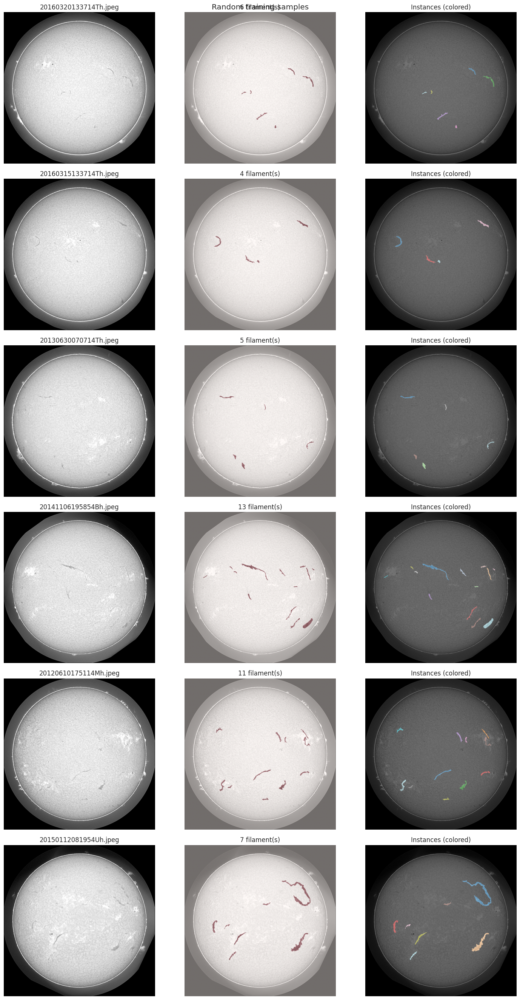

In [6]:
def show_samples(img_ids, n=6, title=""):
    img_ids = random.sample(list(img_ids), min(n, len(img_ids)))
    fig, axes = plt.subplots(len(img_ids), 3, figsize=(15, 4.5 * len(img_ids)))
    if len(img_ids) == 1:
        axes = axes[None, :]

    for i, img_id in enumerate(img_ids):
        img = load_image(id_to_path[img_id])
        combined = get_combined_mask(img_id)
        instances = get_instance_masks(img_id)

        axes[i, 0].imshow(norm01(img), cmap="gray")
        axes[i, 0].set_title(Path(images_info[img_id]["file_name"]).name)

        axes[i, 1].imshow(norm01(img), cmap="gray")
        axes[i, 1].imshow(combined, cmap="Reds", alpha=0.45)
        axes[i, 1].set_title(f"{len(instances)} filament(s)")

        # each instance a different color -> shows if instances matter
        inst_vis = np.zeros((*combined.shape, 3))
        cmap = plt.cm.tab20(np.linspace(0, 1, max(len(instances), 1)))
        for j, m in enumerate(instances):
            inst_vis[m] = cmap[j][:3]
        axes[i, 2].imshow(norm01(img), cmap="gray")
        axes[i, 2].imshow(inst_vis, alpha=0.55)
        axes[i, 2].set_title("Instances (colored)")

        for ax in axes[i]:
            ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(train_ids, n=6, title="Random training samples")


In [7]:
# Image-level stats for all train + test
def img_stats(path, split):
    img = load_image(path)
    return {
        "file": path.name, "split": split,
        "height": img.shape[0], "width": img.shape[1],
        "min": img.min(), "max": img.max(),
        "mean": img.mean(), "std": img.std(),
        "p05": np.percentile(img, 5), "p95": np.percentile(img, 95),
    }

stats_df = pd.DataFrame(
    [img_stats(p, "train") for p in tqdm(train_paths)] +
    [img_stats(p, "test")  for p in tqdm(test_paths)]
)

print("Unique resolutions:")
display(stats_df.groupby("split")[["height", "width"]]
        .apply(lambda d: d.value_counts().head()))

print("\nGrayscale check — dynamic ranges:")
display(stats_df.groupby("split")[["min", "max", "mean", "std"]].describe().round(2))


  0%|          | 0/707 [00:00<?, ?it/s]

  0%|          | 0/180 [00:00<?, ?it/s]

Unique resolutions:


height,2048
width,2048
split,
test,180
train,707



Grayscale check — dynamic ranges:


min                                       max          ...   mean  \
       count mean  std  min  25%  50%  75%  max  count    mean  ...    75%   
split                                                           ...          
test   180.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  180.0  240.23  ...  85.54   
train  707.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  707.0  240.79  ...  85.23   

                std                                                  
         max  count   mean   std    min    25%    50%    75%    max  
split                                                                
test   94.53  180.0  56.49  2.91  49.02  54.83  57.28  58.63  65.37  
train  95.49  707.0  56.70  2.64  49.10  55.20  57.70  58.65  61.50  

[2 rows x 32 columns]

  0%|          | 0/1154 [00:00<?, ?it/s]

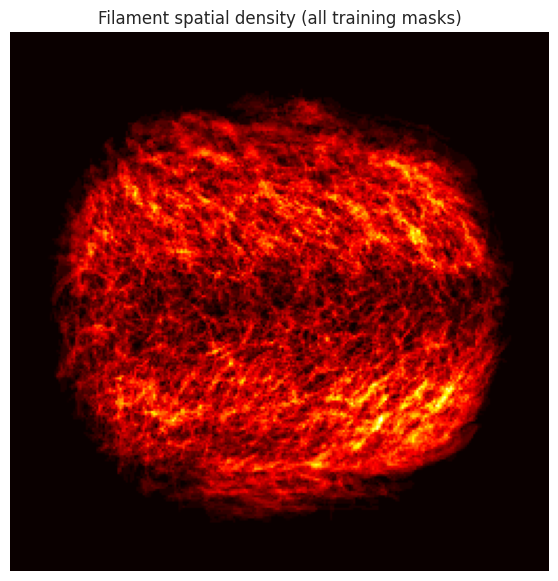

In [8]:
# Spatial characteristics: WHERE do filaments occur? (disk-relative heatmap)
HEAT = np.zeros((256, 256))
for img_id in tqdm(train_ids):
    m = get_combined_mask(img_id)
    if m.any():
        HEAT += cv2.resize(m.astype(np.float32), (256, 256))

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(HEAT, cmap="hot")
ax.set_title("Filament spatial density (all training masks)")
ax.axis("off")
plt.show()


Foreground fraction: median=0.3295%  mean=0.3884%  min=0.0079%  max=1.7339%
Global foreground ratio: 0.3884%

Background: ██████████████████████████████████████████████████ 99.6%
Filament:   █ 0.4%


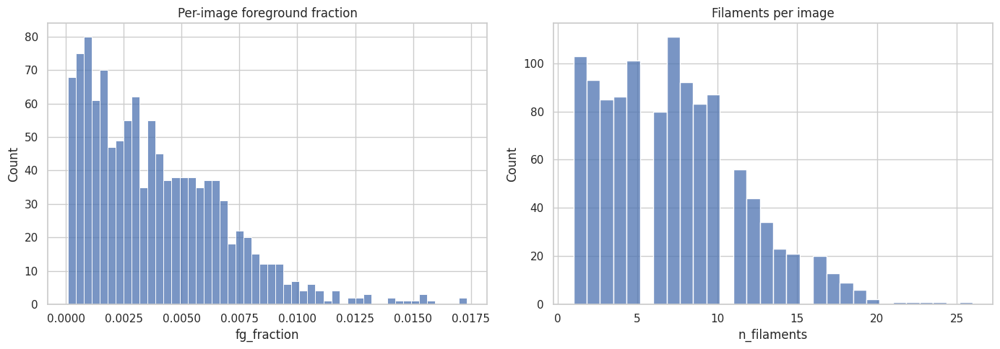

In [9]:
fg = ann_df["fg_fraction"]

print(f"Foreground fraction: median={fg.median():.4%}  "
      f"mean={fg.mean():.4%}  min={fg.min():.4%}  max={fg.max():.4%}")

overall_fg = ann_df["fg_pixels"].sum() / (ann_df["height"] * ann_df["width"]).sum()
print(f"Global foreground ratio: {overall_fg:.4%}")

bar = int(round(overall_fg * 50))
print("\nBackground: " + "█" * (50 - bar) + f" {1-overall_fg:.1%}")
print("Filament:   " + "█" * max(bar, 1) + f" {overall_fg:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(fg, bins=50, ax=axes[0])
axes[0].set_title("Per-image foreground fraction")
sns.histplot(ann_df["n_filaments"], bins=30, ax=axes[1])
axes[1].set_title("Filaments per image")
plt.tight_layout(); plt.show()


  0%|          | 0/1154 [00:00<?, ?it/s]

,area,skeleton_length,mean_thickness,elongation,eccentricity,solidity,n_pieces_in_instance
count,8199.00,8199.00,8199.00,8199.00,8199.00,8199.00,8199.0
mean,2293.71,178.40,11.00,17.00,0.95,0.58,1.0
std,2858.36,159.51,5.14,13.31,0.06,0.18,0.0
min,13.00,3.00,2.93,0.33,0.18,0.10,1.0
25%,757.00,76.00,7.83,7.98,0.95,0.45,1.0
50%,1365.00,129.00,9.74,13.64,0.97,0.57,1.0
75%,2648.50,223.00,12.51,21.83,0.99,0.70,1.0
max,39122.00,1781.00,54.91,154.86,1.00,0.98,1.0



Instances whose OWN mask is already fragmented: 0.0%
(high value => ground truth itself contains broken filaments — important for the fragmentation penalty in Panoptic Quality)


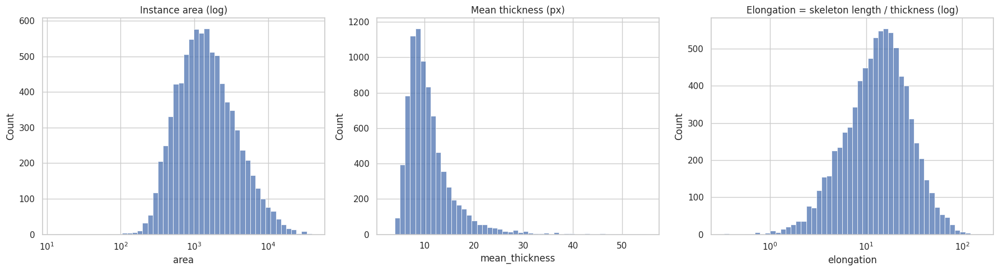

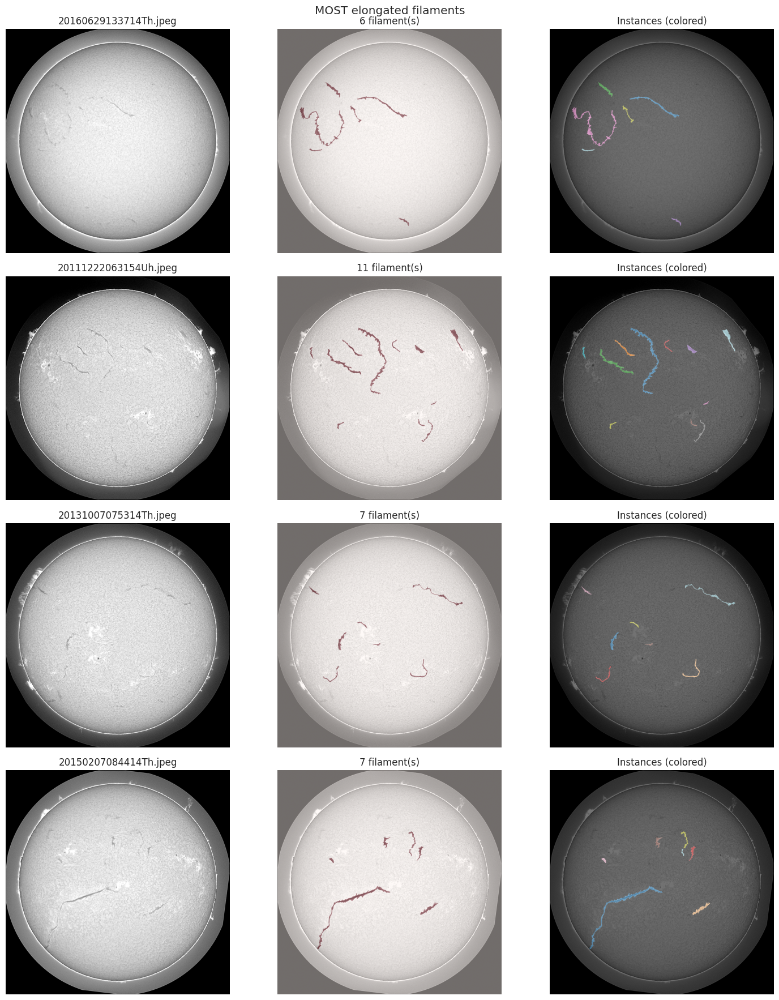

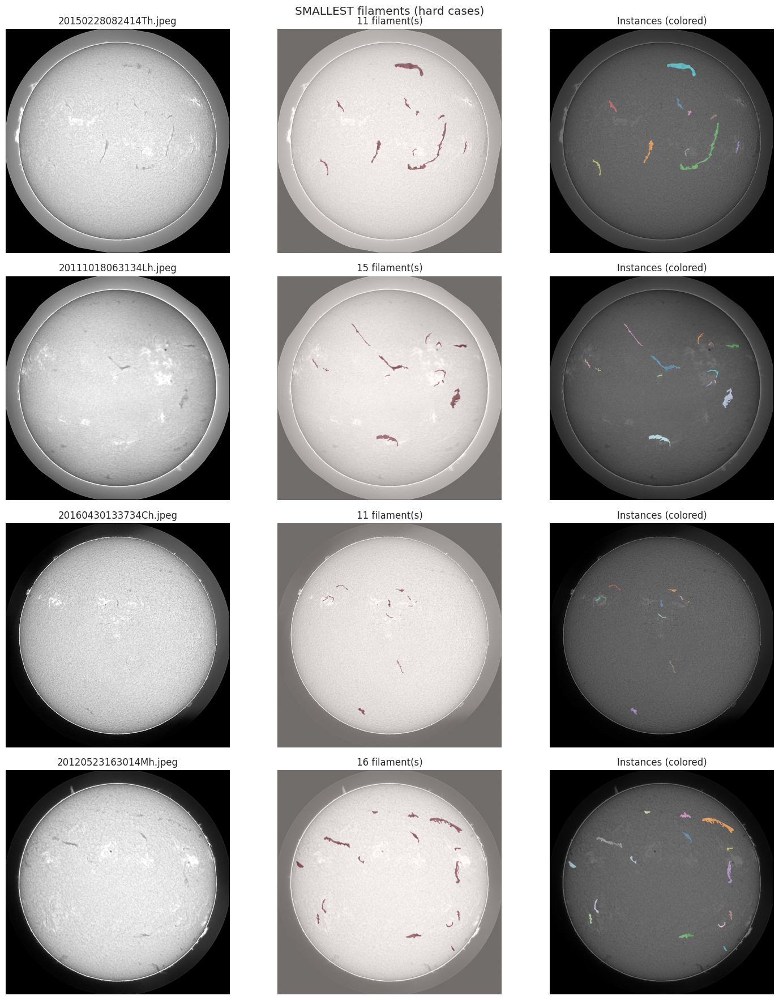

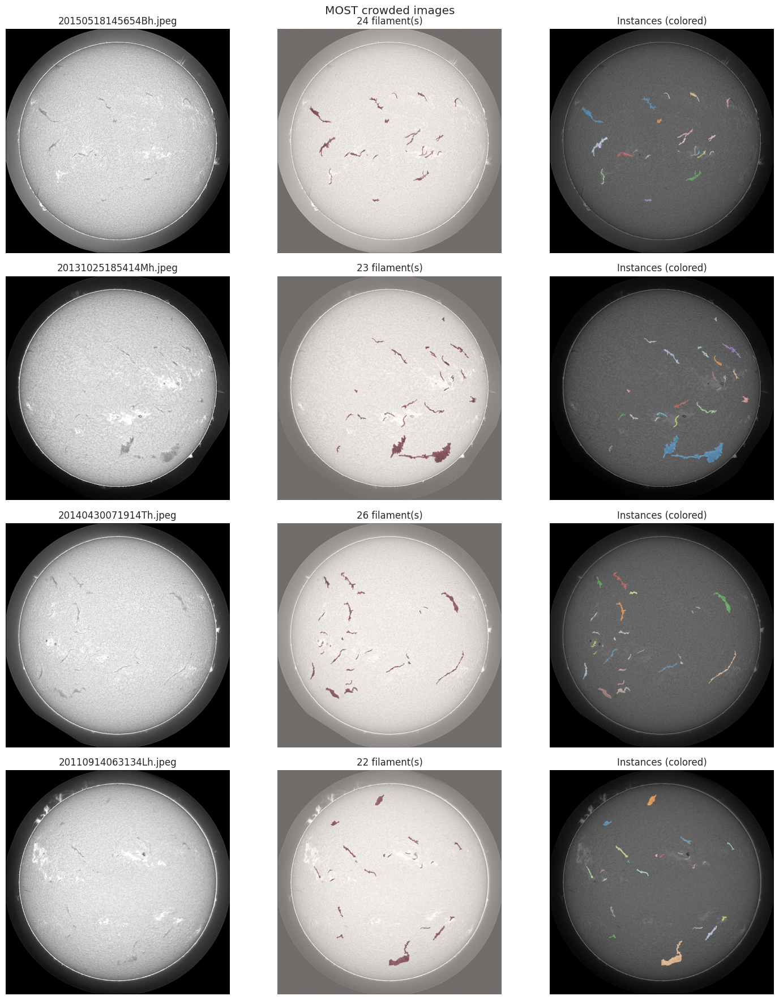

In [10]:
morph_rows = []
for img_id in tqdm(train_ids):
    for m in get_instance_masks(img_id):
        area = int(m.sum())
        if area < 5:
            continue
        lab = measure.label(m)
        props = max(regionprops(lab), key=lambda r: r.area)

        skel = morphology.skeletonize(m)
        skel_len = int(skel.sum())
        dist = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 5)
        thick = dist[skel] * 2 if skel_len else np.array([0.0])

        morph_rows.append({
            "image_id": img_id,
            "area": area,
            "skeleton_length": skel_len,
            "mean_thickness": float(thick.mean()),
            "elongation": skel_len / max(thick.mean(), 1e-6),
            "eccentricity": props.eccentricity,
            "solidity": props.solidity,
            "n_pieces_in_instance": lab.max(),   # >1 = one filament annotated as several blobs!
        })

morph_df = pd.DataFrame(morph_rows)
display(morph_df.describe().round(2))

frag = (morph_df["n_pieces_in_instance"] > 1).mean()
print(f"\nInstances whose OWN mask is already fragmented: {frag:.1%}")
print("(high value => ground truth itself contains broken filaments — "
      "important for the fragmentation penalty in Panoptic Quality)")


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(morph_df["area"], bins=50, log_scale=True, ax=axes[0])
axes[0].set_title("Instance area (log)")
sns.histplot(morph_df["mean_thickness"], bins=50, ax=axes[1])
axes[1].set_title("Mean thickness (px)")
sns.histplot(morph_df["elongation"], bins=50, log_scale=True, ax=axes[2])
axes[2].set_title("Elongation = skeleton length / thickness (log)")
plt.tight_layout(); plt.show()



# Extreme examples worth eyeballing
def show_extremes(df, col, ascending, n=4, label=""):
    ids = df.sort_values(col, ascending=ascending)["image_id"].unique()[:n]
    show_samples(ids, n=n, title=label)

show_extremes(morph_df, "elongation", False, label="MOST elongated filaments")
show_extremes(morph_df, "area", True, label="SMALLEST filaments (hard cases)")
show_extremes(ann_df.set_index("image_id").loc[lambda d: d.n_filaments > 0]
              .reset_index(), "n_filaments", False, label="MOST crowded images")


Phase 1G

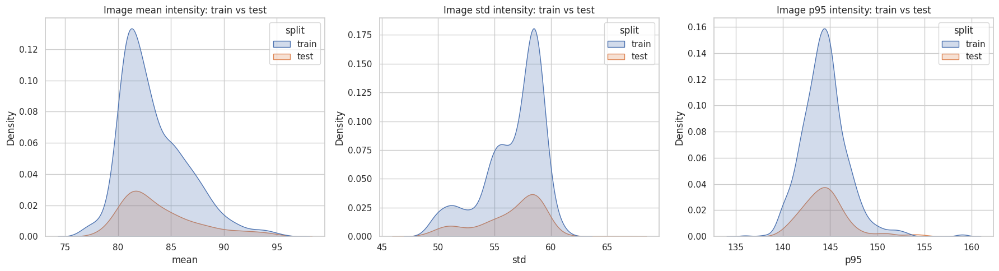

 mean: KS=0.069  p=0.4782
  std: KS=0.063  p=0.6001
  p05: KS=0.000  p=1.0000
  p95: KS=0.025  p=1.0000


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["mean", "std", "p95"]):
    sns.kdeplot(data=stats_df, x=col, hue="split", fill=True, ax=ax)
    ax.set_title(f"Image {col} intensity: train vs test")
plt.tight_layout(); plt.show()

# Quantitative check (KS test)
from scipy.stats import ks_2samp
for col in ["mean", "std", "p05", "p95"]:
    tr = stats_df.loc[stats_df.split == "train", col]
    te = stats_df.loc[stats_df.split == "test", col]
    stat, pval = ks_2samp(tr, te)
    flag = "  <-- SHIFT?" if pval < 0.01 else ""
    print(f"{col:>5}: KS={stat:.3f}  p={pval:.4f}{flag}")


In [12]:
lines = ["=" * 70, "DATASET HYPOTHESIS", "=" * 70]

n_res = stats_df.groupby("split")[["height","width"]].nunique().max().max()
lines.append(f"- {len(train_paths)} train / {len(test_paths)} test images; "
             f"{'uniform' if n_res == 1 else 'VARIABLE'} resolution.")

lines.append(f"- Binary foreground occupies {overall_fg:.2%} of pixels overall "
             f"(median {fg.median():.2%}/image) -> "
             + ("EXTREME sparsity: Dice/Tversky/Focal loss, fg-aware cropping."
                if overall_fg < 0.02 else "moderate imbalance."))

med_e = morph_df["elongation"].median()
med_t = morph_df["mean_thickness"].median()
lines.append(f"- Filaments are elongated (median elongation {med_e:.0f}, "
             f"median thickness {med_t:.1f}px) -> preserve resolution; "
             "thin-structure losses (clDice) worth testing.")

lines.append(f"- Median {ann_df['n_filaments'].median():.0f} filaments/image "
             f"(max {ann_df['n_filaments'].max()}) -> instance separation matters "
             "because the metric is PANOPTIC QUALITY, not plain Dice.")

lines.append(f"- {frag:.0%} of GT instances are internally fragmented -> "
             "connected-components != instances; naive CC post-processing "
             "will be penalized by PQ's one-to-many matching.")

shifts = [c for c in ["mean","std","p05","p95"]
          if ks_2samp(stats_df.loc[stats_df.split=='train', c],
                      stats_df.loc[stats_df.split=='test', c])[1] < 0.01]
lines.append("- Train/test intensity shift detected in: "
             + (", ".join(shifts) + " -> normalization/TTA important."
                if shifts else "none -> distributions aligned."))

hypothesis = "\n".join(lines)
print(hypothesis)

with open("phase1_hypothesis.txt", "w") as f:
    f.write(hypothesis)

ann_df.drop(columns="instance_areas").to_csv("phase1_annotations.csv", index=False)
morph_df.to_csv("phase1_morphology.csv", index=False)
stats_df.to_csv("phase1_image_stats.csv", index=False)
print("\nSaved: phase1_hypothesis.txt + 3 CSVs")


DATASET HYPOTHESIS
- 707 train / 180 test images; uniform resolution.
- Binary foreground occupies 0.39% of pixels overall (median 0.33%/image) -> EXTREME sparsity: Dice/Tversky/Focal loss, fg-aware cropping.
- Filaments are elongated (median elongation 14, median thickness 9.7px) -> preserve resolution; thin-structure losses (clDice) worth testing.
- Median 7 filaments/image (max 26) -> instance separation matters because the metric is PANOPTIC QUALITY, not plain Dice.
- 0% of GT instances are internally fragmented -> connected-components != instances; naive CC post-processing will be penalized by PQ's one-to-many matching.
- Train/test intensity shift detected in: none -> distributions aligned.

Saved: phase1_hypothesis.txt + 3 CSVs
